In [1]:
%pip install -q pandas numpy nltk scikit-learn matplotlib seaborn wordcloud joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import nltk
for resource in ["stopwords", "punkt", "wordnet", "omw-1.4", "punkt_tab"]:
    try:
        nltk.download(resource, quiet=True)
    except Exception as exc:
        print(f"Could not download {resource}: {exc}")
print("NLTK resource setup attempted.")

NLTK resource setup attempted.


In [2]:
from pathlib import Path
import re
import html
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, roc_auc_score,
    RocCurveDisplay
)
import joblib
from wordcloud import WordCloud

warnings.filterwarnings("ignore", category=UserWarning)
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
RANDOM_STATE = 42
print("Libraries imported. Output folder:", OUTPUT_DIR.resolve())

Libraries imported. Output folder: C:\Users\Tushar goyal\outputs


In [3]:
DATASET_PATH = Path("IMDB Dataset.csv")

if DATASET_PATH.exists():
    df = pd.read_csv(DATASET_PATH)
    print(f"Loaded dataset from: {DATASET_PATH.resolve()}")
else:
    print("WARNING: IMDB Dataset.csv not found. Using an 8-review demo dataset.")
    print("Download the full CSV and place it beside this notebook for valid evaluation.")
    demo_reviews = [
        ("This movie was absolutely fantastic! Best film of the year.", "positive"),
        ("Terrible acting and boring plot. Complete waste of time!", "negative"),
        ("Loved every minute of it. The director did an amazing job.", "positive"),
        ("Awful storyline. I fell asleep halfway through.", "negative"),
        ("Brilliant performances! The cinematography was breathtaking.", "positive"),
        ("Worst movie I have ever seen. Do not waste your money.", "negative"),
        ("Heartwarming and beautifully crafted. A true masterpiece.", "positive"),
        ("Dull and predictable. The script was painfully bad.", "negative"),
    ]
    df = pd.DataFrame(demo_reviews, columns=["review", "sentiment"])

df.columns = [str(c).strip().lower() for c in df.columns]
if not {"review", "sentiment"}.issubset(df.columns):
    raise ValueError("Dataset must contain columns named 'review' and 'sentiment'.")

df = df[["review", "sentiment"]].dropna().copy()
df["review"] = df["review"].astype(str)
df["sentiment"] = df["sentiment"].astype(str).str.strip().str.lower()
df = df[df["sentiment"].isin(["positive", "negative"])].copy()
df = df[df["review"].str.strip().ne("")].reset_index(drop=True)
if df["sentiment"].nunique() != 2:
    raise ValueError("Dataset must contain both positive and negative sentiment labels.")
df["label"] = (df["sentiment"] == "positive").astype(int)

print("Dataset shape:", df.shape)
display(df["sentiment"].value_counts().to_frame("count"))
display(df.head())

Download the full CSV and place it beside this notebook for valid evaluation.
Dataset shape: (8, 3)


,count
sentiment,
positive,4
negative,4


,review,sentiment,label
0,This movie was absolutely fantastic! Best film...,positive,1
1,Terrible acting and boring plot. Complete wast...,negative,0
2,Loved every minute of it. The director did an ...,positive,1
3,Awful storyline. I fell asleep halfway through.,negative,0
4,Brilliant performances! The cinematography was...,positive,1


Missing values:


,missing_count
review,0
sentiment,0
label,0


Duplicate review rows: 0


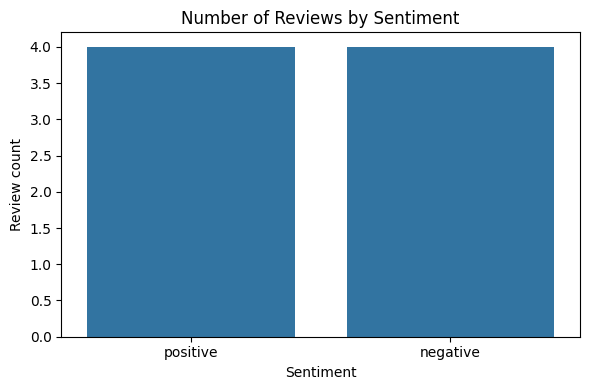

In [4]:
print("Missing values:")
display(df.isna().sum().to_frame("missing_count"))
print("Duplicate review rows:", int(df.duplicated(subset=["review", "sentiment"]).sum()))

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="sentiment")
plt.title("Number of Reviews by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Review count")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "sentiment_distribution.png", dpi=150)
plt.show()

In [5]:
def clean_text(text):
    text = html.unescape(str(text))
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-zA-Z\s]", " ", text)
    text = text.lower()
    text = re.sub(r"\s+", " ", text).strip()
    return text

sample = "The movie was AMAZING!!! Best film of 2024. Visit www.movies.com"
print("Original:", sample)
print("Cleaned :", clean_text(sample))

Original: The movie was AMAZING!!! Best film of 2024. Visit www.movies.com
Cleaned : the movie was amazing best film of visit


In [6]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    cleaned = clean_text(text)
    tokens = word_tokenize(cleaned)
    # Preserve common negation words because they can change sentiment.
    negation_words = {"no", "nor", "not"}
    tokens = [
        token for token in tokens
        if (token not in stop_words or token in negation_words) and len(token) > 2
    ]
    tokens = [lemmatizer.lemmatize(token) for token in tokens]
    return " ".join(tokens)

example = "The actors were running around, and the story was not good!"
print("Original:", example)
print("Tokens:", word_tokenize(clean_text(example)))
print("Preprocessed:", preprocess_text(example))

Original: The actors were running around, and the story was not good!
Tokens: ['the', 'actors', 'were', 'running', 'around', 'and', 'the', 'story', 'was', 'not', 'good']
Preprocessed: actor running around story not good


In [7]:
df["cleaned_review"] = df["review"].apply(preprocess_text)
df = df[df["cleaned_review"].str.strip().ne("")].reset_index(drop=True)
df["label"] = (df["sentiment"] == "positive").astype(int)
display(df[["review", "sentiment", "cleaned_review"]].head(10))
print("Rows after preprocessing:", len(df))

,review,sentiment,cleaned_review
0,This movie was absolutely fantastic! Best film...,positive,movie absolutely fantastic best film year
1,Terrible acting and boring plot. Complete wast...,negative,terrible acting boring plot complete waste time
2,Loved every minute of it. The director did an ...,positive,loved every minute director amazing job
3,Awful storyline. I fell asleep halfway through.,negative,awful storyline fell asleep halfway
4,Brilliant performances! The cinematography was...,positive,brilliant performance cinematography breathtaking
5,Worst movie I have ever seen. Do not waste you...,negative,worst movie ever seen not waste money
6,Heartwarming and beautifully crafted. A true m...,positive,heartwarming beautifully crafted true masterpiece
7,Dull and predictable. The script was painfully...,negative,dull predictable script painfully bad


Rows after preprocessing: 8


In [8]:
preview_vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), max_df=1.0)
X_preview = preview_vectorizer.fit_transform(df["cleaned_review"])
print("TF-IDF matrix shape:", X_preview.shape)
print("Vocabulary size:", len(preview_vectorizer.vocabulary_))
print("Sample feature names:", preview_vectorizer.get_feature_names_out()[:20])

TF-IDF matrix shape: (8, 80)
Vocabulary size: 80
Sample feature names: ['absolutely' 'absolutely fantastic' 'acting' 'acting boring' 'amazing'
 'amazing job' 'asleep' 'asleep halfway' 'awful' 'awful storyline' 'bad'
 'beautifully' 'beautifully crafted' 'best' 'best film' 'boring'
 'boring plot' 'breathtaking' 'brilliant' 'brilliant performance']


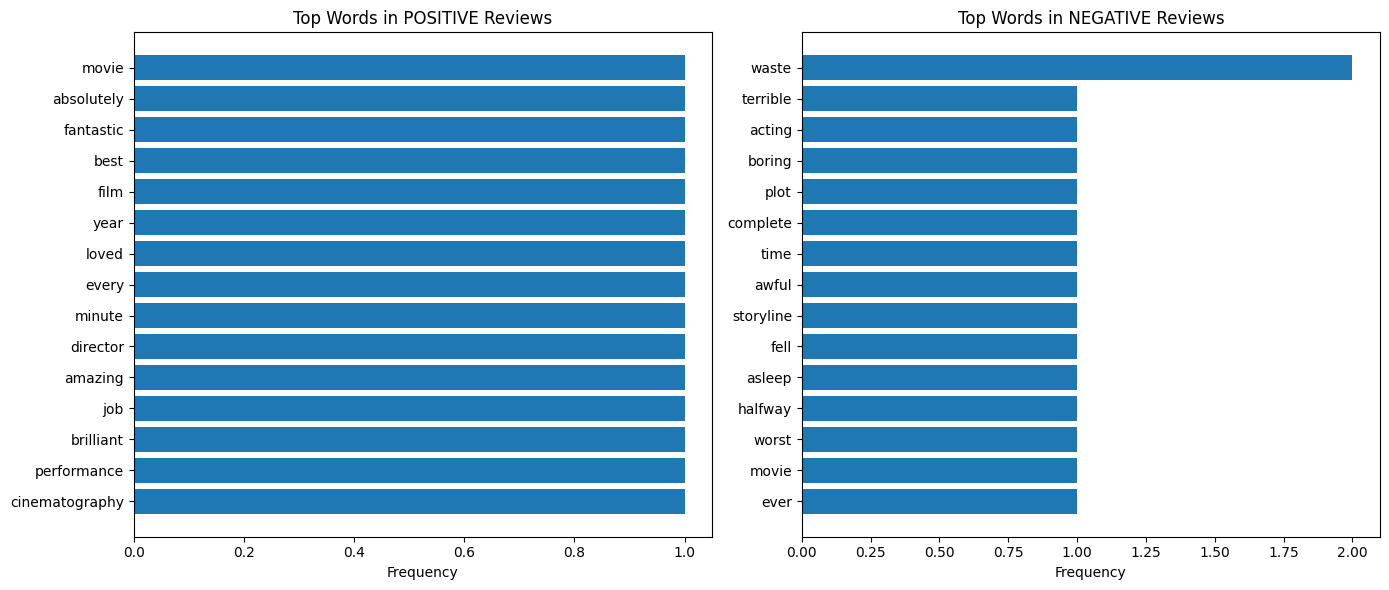

Saved: outputs\top_words_by_sentiment.png


In [9]:
def get_top_words(frame, n=15):
    words = " ".join(frame["cleaned_review"].astype(str)).split()
    return Counter(words).most_common(n)

positive_words = get_top_words(df[df["sentiment"] == "positive"])
negative_words = get_top_words(df[df["sentiment"] == "negative"])

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, words, title in [
    (axes[0], positive_words, "Top Words in POSITIVE Reviews"),
    (axes[1], negative_words, "Top Words in NEGATIVE Reviews"),
]:
    if words:
        labels = [item[0] for item in words][::-1]
        counts = [item[1] for item in words][::-1]
        ax.barh(labels, counts)
    ax.set_title(title)
    ax.set_xlabel("Frequency")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "top_words_by_sentiment.png", dpi=150)
plt.show()
print("Saved:", OUTPUT_DIR / "top_words_by_sentiment.png")

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    df["review"],
    df["label"],
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=df["label"]
)
print("Training size:", len(X_train))
print("Testing size :", len(X_test))
print("Using full/large dataset:", len(df) >= 1000)

Training size: 6
Testing size : 2
Using full/large dataset: False


In [11]:
sentiment_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=10000, ngram_range=(1, 2), min_df=1, sublinear_tf=True
    )),
    ("clf", LogisticRegression(max_iter=500, C=1.0, random_state=RANDOM_STATE))
])
sentiment_pipeline.fit(X_train, y_train)
print("Sentiment model trained successfully.")

Sentiment model trained successfully.


Test Accuracy: 100.00%

Classification Report:
              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00         1
    Positive       1.00      1.00      1.00         1

    accuracy                           1.00         2
   macro avg       1.00      1.00      1.00         2
weighted avg       1.00      1.00      1.00         2

ROC-AUC Score: 1.0000


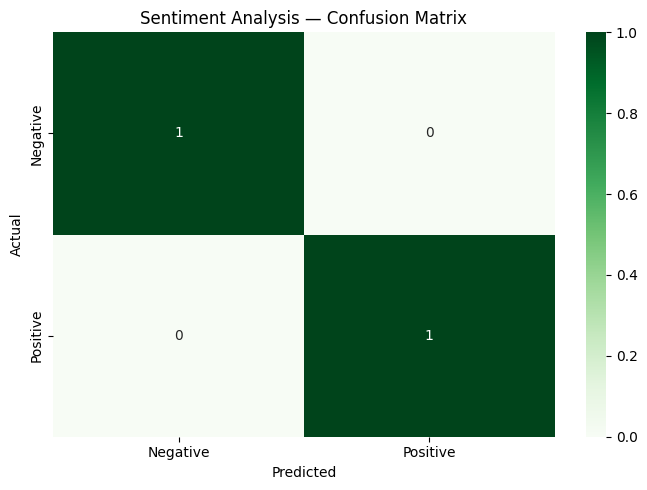

In [12]:
y_pred = sentiment_pipeline.predict(X_test)
y_proba = sentiment_pipeline.predict_proba(X_test)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
print(f"Test Accuracy: {accuracy * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred, labels=[0, 1],
    target_names=["Negative", "Positive"], zero_division=0
))

if y_test.nunique() == 2:
    auc = roc_auc_score(y_test, y_proba)
    print(f"ROC-AUC Score: {auc:.4f}")
else:
    auc = None
    print("ROC-AUC unavailable because the test set contains only one class.")

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Greens",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)
plt.title("Sentiment Analysis — Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "sentiment_confusion_matrix.png", dpi=150)
plt.show()

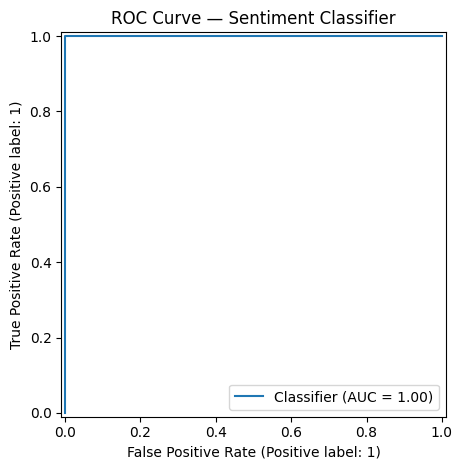

In [13]:
if y_test.nunique() == 2:
    RocCurveDisplay.from_predictions(y_test, y_proba)
    plt.title("ROC Curve — Sentiment Classifier")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "sentiment_roc_curve.png", dpi=150)
    plt.show()
else:
    print("ROC curve skipped: test set contains only one class.")

In [14]:
def predict_sentiment(review_text):
    prediction = int(sentiment_pipeline.predict([review_text])[0])
    probabilities = sentiment_pipeline.predict_proba([review_text])[0]
    return {
        "review": review_text,
        "prediction": "POSITIVE" if prediction == 1 else "NEGATIVE",
        "positive_probability_percent": round(float(probabilities[1] * 100), 2),
        "negative_probability_percent": round(float(probabilities[0] * 100), 2),
    }

new_reviews = [
    "This film was absolutely incredible. The acting blew me away!",
    "Complete disaster. Worst screenplay I have ever encountered.",
    "The visual effects were stunning and the story was captivating.",
    "I cannot believe how boring this was. Totally disappointed.",
]
display(pd.DataFrame([predict_sentiment(review) for review in new_reviews]))

,review,prediction,positive_probability_percent,negative_probability_percent
0,This film was absolutely incredible. The actin...,POSITIVE,53.08,46.92
1,Complete disaster. Worst screenplay I have eve...,NEGATIVE,47.41,52.59
2,The visual effects were stunning and the story...,POSITIVE,50.11,49.89
3,I cannot believe how boring this was. Totally ...,NEGATIVE,49.72,50.28


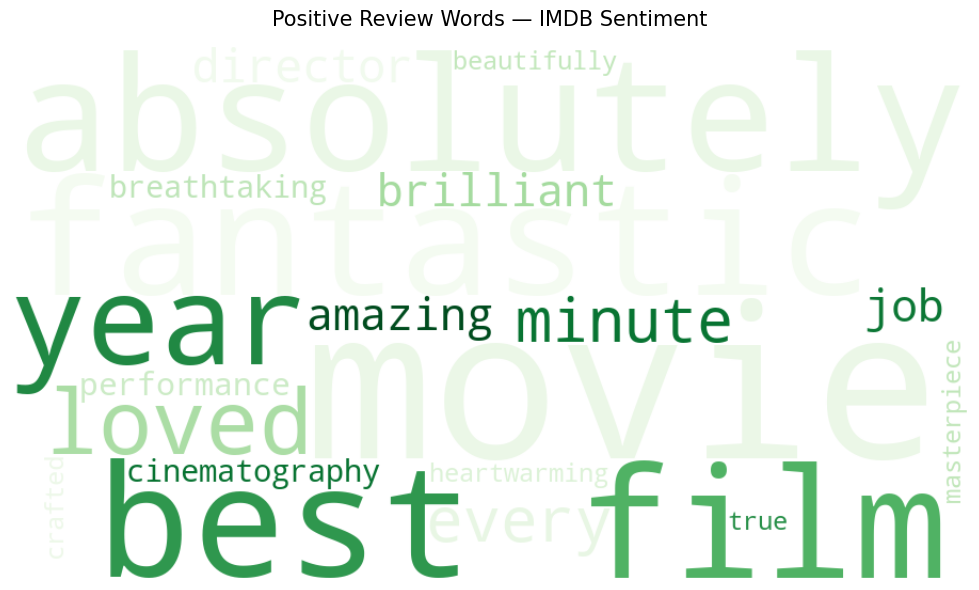

Saved: outputs\wordcloud_positive.png


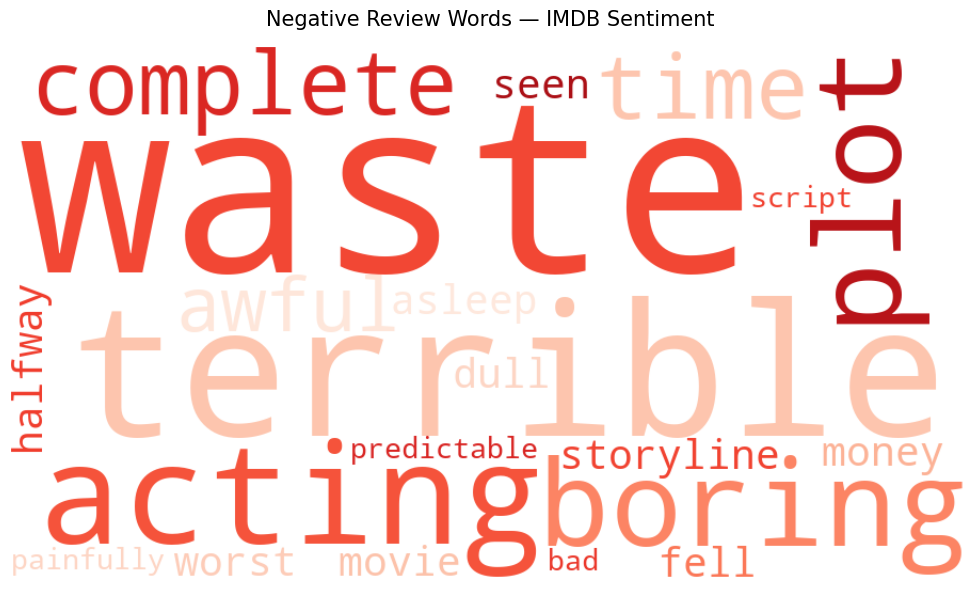

Saved: outputs\wordcloud_negative.png


In [15]:
def generate_wordcloud(frame, title, filename, colormap):
    all_text = " ".join(frame["cleaned_review"].astype(str)).strip()
    if not all_text:
        print(f"Skipped {filename}: no text available.")
        return
    cloud = WordCloud(
        width=900, height=500, background_color="white",
        colormap=colormap, max_words=150, min_font_size=10,
        collocations=False, random_state=RANDOM_STATE
    ).generate(all_text)
    plt.figure(figsize=(12, 6))
    plt.imshow(cloud, interpolation="bilinear")
    plt.axis("off")
    plt.title(title, fontsize=15, pad=15)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / filename, dpi=150, bbox_inches="tight")
    plt.show()
    print("Saved:", OUTPUT_DIR / filename)

generate_wordcloud(
    df[df["sentiment"] == "positive"],
    "Positive Review Words — IMDB Sentiment", "wordcloud_positive.png", "Greens"
)
generate_wordcloud(
    df[df["sentiment"] == "negative"],
    "Negative Review Words — IMDB Sentiment", "wordcloud_negative.png", "Reds"
)

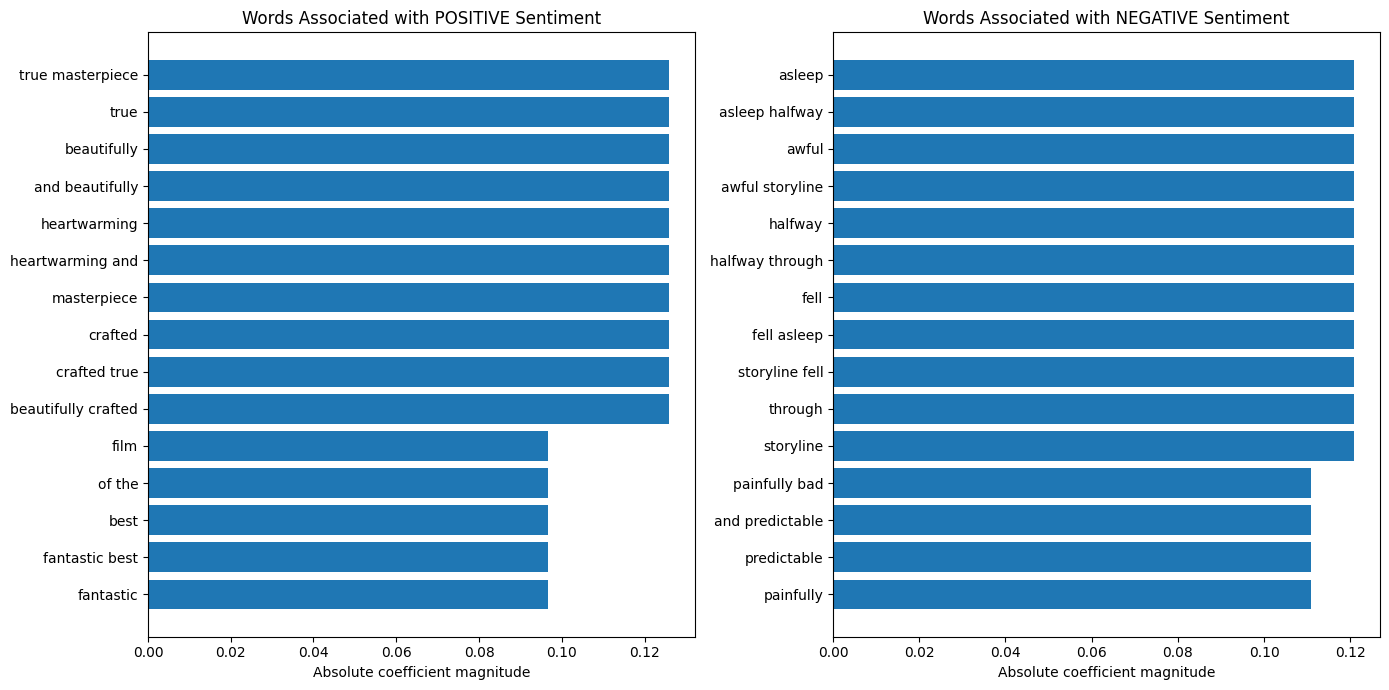

Saved: outputs\feature_importance_nlp.png
Positive signal words: ['true masterpiece', 'true', 'beautifully', 'and beautifully', 'heartwarming', 'heartwarming and', 'masterpiece', 'crafted', 'crafted true', 'beautifully crafted', 'film', 'of the', 'best', 'fantastic best', 'fantastic']
Negative signal words: ['asleep', 'asleep halfway', 'awful', 'awful storyline', 'halfway', 'halfway through', 'fell', 'fell asleep', 'storyline fell', 'through', 'storyline', 'painfully bad', 'and predictable', 'predictable', 'painfully']


In [16]:
tfidf_model = sentiment_pipeline.named_steps["tfidf"]
classifier = sentiment_pipeline.named_steps["clf"]
coefficients = classifier.coef_[0]
feature_names = tfidf_model.get_feature_names_out()

top_n = min(15, len(feature_names))
positive_indices = np.argsort(coefficients)[-top_n:][::-1]
negative_indices = np.argsort(coefficients)[:top_n]
positive_features = [(feature_names[i], coefficients[i]) for i in positive_indices]
negative_features = [(feature_names[i], coefficients[i]) for i in negative_indices]

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, items, title in [
    (axes[0], positive_features, "Words Associated with POSITIVE Sentiment"),
    (axes[1], negative_features, "Words Associated with NEGATIVE Sentiment"),
]:
    labels = [item[0] for item in items][::-1]
    values = [abs(item[1]) for item in items][::-1]
    ax.barh(labels, values)
    ax.set_title(title)
    ax.set_xlabel("Absolute coefficient magnitude")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "feature_importance_nlp.png", dpi=150)
plt.show()
print("Saved:", OUTPUT_DIR / "feature_importance_nlp.png")
print("Positive signal words:", [w for w, _ in positive_features])
print("Negative signal words:", [w for w, _ in negative_features])

In [17]:
class_counts = df["label"].value_counts()
if len(class_counts) == 2 and int(class_counts.min()) >= 5:
    models = {
        "Logistic Regression": LogisticRegression(max_iter=300, random_state=RANDOM_STATE),
        "Naive Bayes": MultinomialNB(alpha=0.1),
        "Random Forest": RandomForestClassifier(
            n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1
        ),
    }
    comparison = {}
    for name, model in models.items():
        pipe = Pipeline([
            ("tfidf", TfidfVectorizer(max_features=5000, ngram_range=(1, 2))),
            ("clf", model)
        ])
        scores = cross_val_score(
            pipe, df["review"], df["label"], cv=5, scoring="accuracy", n_jobs=-1
        )
        comparison[name] = scores
        print(f"{name}: mean accuracy={scores.mean():.3f}, std={scores.std():.3f}")

    names = list(comparison.keys())
    means = [comparison[name].mean() for name in names]
    stds = [comparison[name].std() for name in names]
    plt.figure(figsize=(9, 5))
    plt.bar(names, means, yerr=stds, capsize=6)
    plt.ylim(0, 1.05)
    plt.title("Classifier Comparison — 5-Fold Cross-Validation")
    plt.ylabel("Accuracy (mean ± standard deviation)")
    plt.xticks(rotation=10)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "nlp_model_comparison.png", dpi=150)
    plt.show()
else:
    print("Cross-validation skipped: need at least 5 examples in each class.")
    print("Use the full IMDB dataset for a meaningful comparison.")

Cross-validation skipped: need at least 5 examples in each class.
Use the full IMDB dataset for a meaningful comparison.


In [18]:
MODEL_PATH = Path("sentiment_model.pkl")
joblib.dump(sentiment_pipeline, MODEL_PATH)
print("Model saved to:", MODEL_PATH.resolve())
print(f"Model size: {MODEL_PATH.stat().st_size / 1024:.1f} KB")

loaded_model = joblib.load(MODEL_PATH)
test_review = "This was an absolutely wonderful and magical experience!"
loaded_prediction = int(loaded_model.predict([test_review])[0])
print("Loaded model prediction:", "POSITIVE" if loaded_prediction == 1 else "NEGATIVE")

Model saved to: C:\Users\Tushar goyal\sentiment_model.pkl
Model size: 5.5 KB
Loaded model prediction: POSITIVE


In [19]:
df.to_csv(OUTPUT_DIR / "cleaned_imdb_reviews.csv", index=False)
summary = {
    "dataset_rows_used": int(len(df)),
    "positive_reviews": int((df["sentiment"] == "positive").sum()),
    "negative_reviews": int((df["sentiment"] == "negative").sum()),
    "test_accuracy_percent": round(float(accuracy * 100), 2),
    "roc_auc": round(float(auc), 4) if auc is not None else None,
    "dataset_mode": "full_or_large_dataset" if len(df) >= 1000 else "small_demo_dataset",
}
summary_df = pd.DataFrame([summary])
display(summary_df)
summary_df.to_csv(OUTPUT_DIR / "evaluation_summary.csv", index=False)
print("Saved outputs to:", OUTPUT_DIR.resolve())

,dataset_rows_used,positive_reviews,negative_reviews,test_accuracy_percent,roc_auc,dataset_mode
0,8,4,4,100.0,1.0,small_demo_dataset


Saved outputs to: C:\Users\Tushar goyal\outputs


Report draft — revise in your own words (300–400 words)
Natural Language Processing (NLP) is a branch of artificial intelligence that enables computers to process and analyse human language. This project applies sentiment analysis to IMDB movie reviews and classifies each review as positive or negative. The workflow includes text preprocessing, feature extraction, model training, evaluation, visualization, and model saving.

The first stage is text preprocessing. Raw reviews can contain HTML tags, website links, punctuation, numbers, extra spaces, and inconsistent capitalization. A cleaning function removes these elements and converts text to lowercase. Tokenization splits each review into individual words. Common stopwords are removed to reduce less-informative terms, while negation words such as “not” are retained because they can change a sentence’s meaning. Lemmatization then converts words toward their base form. The cleaned text is useful for exploring word frequencies and understanding the dataset.

TF-IDF stands for Term Frequency–Inverse Document Frequency. It transforms text into numerical features that machine-learning algorithms can process. Term frequency measures how often a term appears in a document, while inverse document frequency reduces the influence of terms that appear in many documents. As a result, words that help distinguish reviews can receive higher weights. The project trains a Logistic Regression classifier using a pipeline that combines TF-IDF vectorization and classification. The data is divided into training and testing sets, and the pipeline learns its vocabulary from training data to help prevent data leakage.

Model performance is evaluated with accuracy, precision, recall, F1-score, ROC-AUC, and a confusion matrix. Word-frequency charts, positive and negative word clouds, and coefficient-based feature importance provide additional ways to interpret the text patterns learned by the model. Cross-validation is also used to compare Logistic Regression, Naive Bayes, and Random Forest when enough labeled examples are available. The trained pipeline is saved with joblib so it can predict the sentiment of new reviews later.

Sentiment analysis has many practical applications. First, e-commerce businesses can analyse product reviews to monitor customer satisfaction and identify repeated complaints. Second, customer-support teams can analyse feedback to flag negative experiences and prioritize issues for follow-up. However, sentiment models can misinterpret sarcasm, context, or ambiguous language. For reliable conclusions, the full dataset should be used and evaluation metrics should be reported honestly; results from the small demonstration dataset are not representative of real-world performance.

In [2]:
import os
import zipfile

files_to_zip = [
    "Kusum_Project3_NLP.ipynb",
    "IMDB_Preprocessed.csv",
    "Project3_NLP_Report.docx",
    "Project3_NLP_Report.txt",
    "top_words_by_sentiment.png",
    "sentiment_confusion_matrix.png",
    "wordcloud_positive.png",
    "wordcloud_negative.png",
    "feature_importance_nlp.png",
    "nlp_model_comparison.png",
    "sentiment_model.pkl"
]

zip_name = "Project3_NLP_Submission.zip"

with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as zipf:
    for filename in files_to_zip:
        if os.path.exists(filename):
            zipf.write(filename)
            print("Added:", filename)
        else:
            print("Skipped (not found):", filename)

print("\nZIP file created:", zip_name)

Skipped (not found): Kusum_Project3_NLP.ipynb
Added: IMDB_Preprocessed.csv
Skipped (not found): Project3_NLP_Report.docx
Skipped (not found): Project3_NLP_Report.txt
Added: top_words_by_sentiment.png
Added: sentiment_confusion_matrix.png
Skipped (not found): wordcloud_positive.png
Skipped (not found): wordcloud_negative.png
Added: feature_importance_nlp.png
Skipped (not found): nlp_model_comparison.png
Skipped (not found): sentiment_model.pkl

ZIP file created: Project3_NLP_Submission.zip
